# 5 — Model equivalence (Real vs Synthetic vs Augmented)

At **full train size**, we compare three training arms:

| Arm | Training data |
|-----|----------------|
| **R** | Real train fold only |
| **S** | Synthetic pool only (matched to train size) |
| **R+S** | Real train + synthetic top-up to 2× train size |

All models are evaluated on **real** data only:

1. **Internal test** (30% development hold-out)
2. **External validation** (NHANES 2013–2014 complete cases)

Primary model: **Logistic Regression** (paper). Additional models available in the loop below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from experiment_utils import (
    TRAIN_PATH,
    TEST_PATH,
    EXTERNAL_CLEAN_PATH,
    CTGAN_POOL_PATH,
    FIGURES_DIR,
    MODEL_FEATURES,
    LABEL_COL,
    RANDOM_STATE,
    train_model,
    evaluate_model,
    stratified_subsample,
    plot_roc_curves,
    plot_confusion,
    ensure_dirs,
)

ensure_dirs()

PRIMARY_MODEL = 'LR'
MODELS_TO_RUN = ['LR', 'RF', 'GBM', 'SVM', 'NB', 'ANN']  # extend to all six for supplement tables

## 5.1 Load data and build training arms

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
external_df = pd.read_csv(EXTERNAL_CLEAN_PATH)
synthetic_pool = pd.read_csv(CTGAN_POOL_PATH)

n_train = len(train_df)
synthetic_matched = stratified_subsample(
    synthetic_pool, n=n_train, random_state=RANDOM_STATE,
)
synthetic_extra = stratified_subsample(
    synthetic_pool, n=n_train, random_state=RANDOM_STATE + 1,
)
train_augmented = pd.concat([train_df, synthetic_extra], ignore_index=True)

arms = {
    'R (real)': train_df,
    'S (synthetic)': synthetic_matched,
    'R+S (augmented)': train_augmented,
}

for name, df in arms.items():
    print(f'{name:18s} N={len(df):5d}  TARGET={df[LABEL_COL].mean():.3f}')

R (real)           N= 1813  TARGET=0.474
S (synthetic)      N= 1813  TARGET=0.472
R+S (augmented)    N= 3626  TARGET=0.473


## 5.2 Train and evaluate each arm

In [3]:
results_internal = {}
results_external = {}
fitted_models = {}

y_test = test_df[LABEL_COL]
y_ext = external_df[LABEL_COL]

for arm_name, train_arm in arms.items():
    for model_name in MODELS_TO_RUN:
        key = f'{arm_name} | {model_name}'
        print(f'Training {key}...')
        model = train_model(
            train_arm[MODEL_FEATURES],
            train_arm[LABEL_COL],
            model_name=model_name,
            fast=(model_name != PRIMARY_MODEL),
        )
        fitted_models[key] = model

        internal = evaluate_model(model, test_df, y_test)
        external = evaluate_model(model, external_df, y_ext)

        results_internal[key] = {
            'auc': internal['auc'],
            'y_true': y_test,
            'y_proba': internal['y_proba'],
            'cm': internal['confusion_matrix'],
        }
        results_external[key] = {
            'auc': external['auc'],
            'y_true': y_ext,
            'y_proba': external['y_proba'],
            'cm': external['confusion_matrix'],
        }

        print(f'  internal AUC={internal["auc"]:.3f}  external AUC={external["auc"]:.3f}')

Training R (real) | LR...
  internal AUC=0.771  external AUC=0.765
Training R (real) | RF...
  internal AUC=0.753  external AUC=0.745
Training R (real) | GBM...
  internal AUC=0.769  external AUC=0.754
Training R (real) | SVM...
  internal AUC=0.766  external AUC=0.749
Training R (real) | NB...
  internal AUC=0.749  external AUC=0.725
Training R (real) | ANN...
  internal AUC=0.678  external AUC=0.699
Training S (synthetic) | LR...
  internal AUC=0.753  external AUC=0.738
Training S (synthetic) | RF...
  internal AUC=0.707  external AUC=0.709
Training S (synthetic) | GBM...
  internal AUC=0.714  external AUC=0.709
Training S (synthetic) | SVM...
  internal AUC=0.721  external AUC=0.709
Training S (synthetic) | NB...
  internal AUC=0.727  external AUC=0.699
Training S (synthetic) | ANN...
  internal AUC=0.647  external AUC=0.627
Training R+S (augmented) | LR...
  internal AUC=0.768  external AUC=0.761
Training R+S (augmented) | RF...
  internal AUC=0.745  external AUC=0.734
Training R+S

## 5.3 Results tables

In [4]:
def to_table(results):
    rows = []
    for key, val in results.items():
        arm, model = key.split(' | ')
        rows.append({'arm': arm, 'model': model, 'AUC': val['auc']})
    return pd.DataFrame(rows).sort_values(['model', 'arm'])

internal_table = to_table(results_internal)
external_table = to_table(results_external)

print('=== Internal test (real) ===')
print(internal_table.to_string(index=False))
print('\n=== External 2013–2014 (real) ===')
print(external_table.to_string(index=False))

internal_table.to_csv(FIGURES_DIR / 'equivalence_auc_internal.csv', index=False)
external_table.to_csv(FIGURES_DIR / 'equivalence_auc_external.csv', index=False)

=== Internal test (real) ===
            arm model      AUC
       R (real)   ANN 0.678415
R+S (augmented)   ANN 0.721338
  S (synthetic)   ANN 0.647060
       R (real)   GBM 0.769018
R+S (augmented)   GBM 0.755574
  S (synthetic)   GBM 0.713976
       R (real)    LR 0.771496
R+S (augmented)    LR 0.768104
  S (synthetic)    LR 0.753354
       R (real)    NB 0.748756
R+S (augmented)    NB 0.739804
  S (synthetic)    NB 0.727248
       R (real)    RF 0.753129
R+S (augmented)    RF 0.744969
  S (synthetic)    RF 0.707287
       R (real)   SVM 0.766202
R+S (augmented)   SVM 0.762743
  S (synthetic)   SVM 0.721407

=== External 2013–2014 (real) ===
            arm model      AUC
       R (real)   ANN 0.698872
R+S (augmented)   ANN 0.699979
  S (synthetic)   ANN 0.627051
       R (real)   GBM 0.753717
R+S (augmented)   GBM 0.750850
  S (synthetic)   GBM 0.708877
       R (real)    LR 0.765476
R+S (augmented)    LR 0.760694
  S (synthetic)    LR 0.738166
       R (real)    NB 0.725282
R+S (a

## 5.4 ROC curves — Logistic Regression

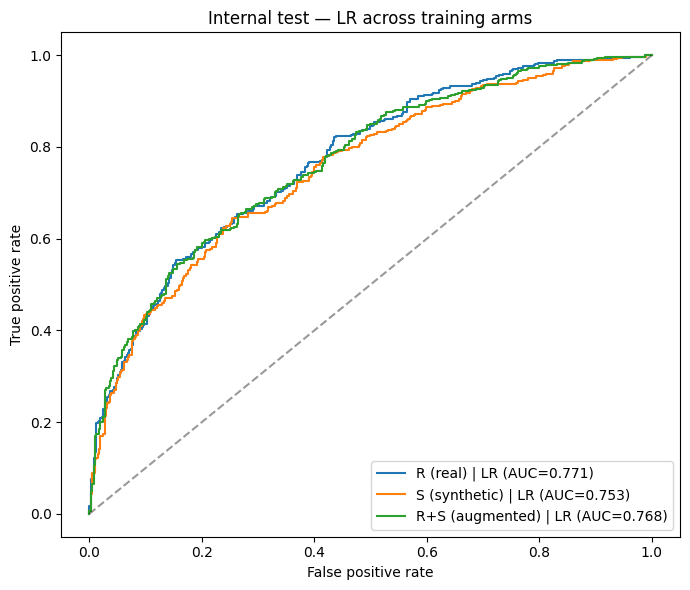

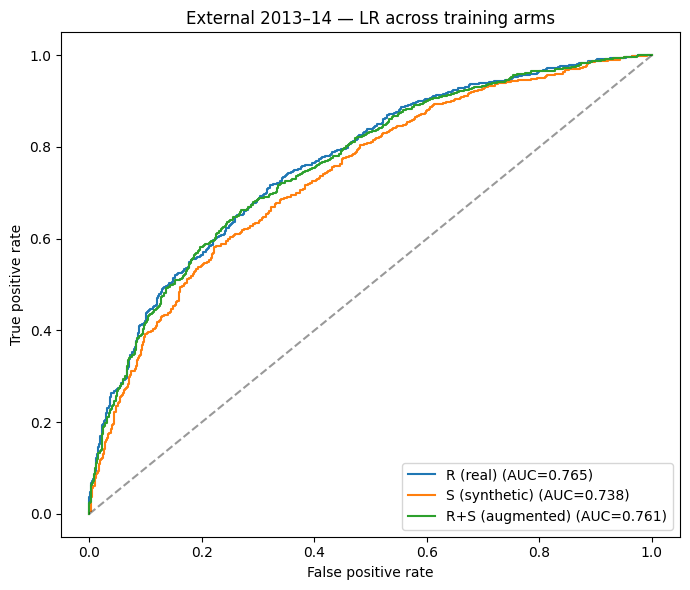

In [5]:
lr_internal = {k: v for k, v in results_internal.items() if k.endswith('| LR')}
lr_external = {k.split(' | ')[0]: v for k, v in results_external.items() if k.endswith('| LR')}

plot_roc_curves(
    lr_internal,
    'Internal test — LR across training arms',
    FIGURES_DIR / 'equivalence_roc_internal_lr.png',
)
plot_roc_curves(
    lr_external,
    'External 2013–14 — LR across training arms',
    FIGURES_DIR / 'equivalence_roc_external_lr.png',
)

## 5.5 Bar chart — external AUC (LR only)

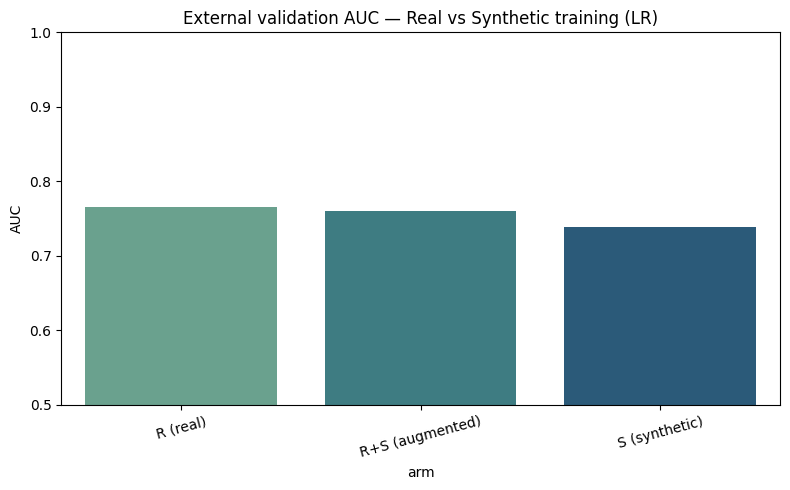

In [6]:
plot_df = external_table[external_table['model'] == 'LR'].copy()
plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x='arm', y='AUC', hue='arm', dodge=False, palette='crest')
plt.ylim(0.5, 1.0)
plt.title('External validation AUC — Real vs Synthetic training (LR)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'linkedin_equivalence_external_auc.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.6 Visual summary — all models

Grouped **bar charts** (one panel per test set) are the clearest way to compare all six classifiers across training arms **R**, **S**, and **R+S**. A companion **heatmap** gives the same numbers in compact form. **ROC grids** (one subplot per classifier) show discrimination curves for each arm.

| Figure | What it shows |
|--------|----------------|
| Bar chart (2 panels) | Internal test vs external 2013–14; hue = training arm |
| Heatmap (2 panels) | AUC matrix: classifier × training arm |
| ROC grids | R / S / R+S curves per classifier, separately for each test set |

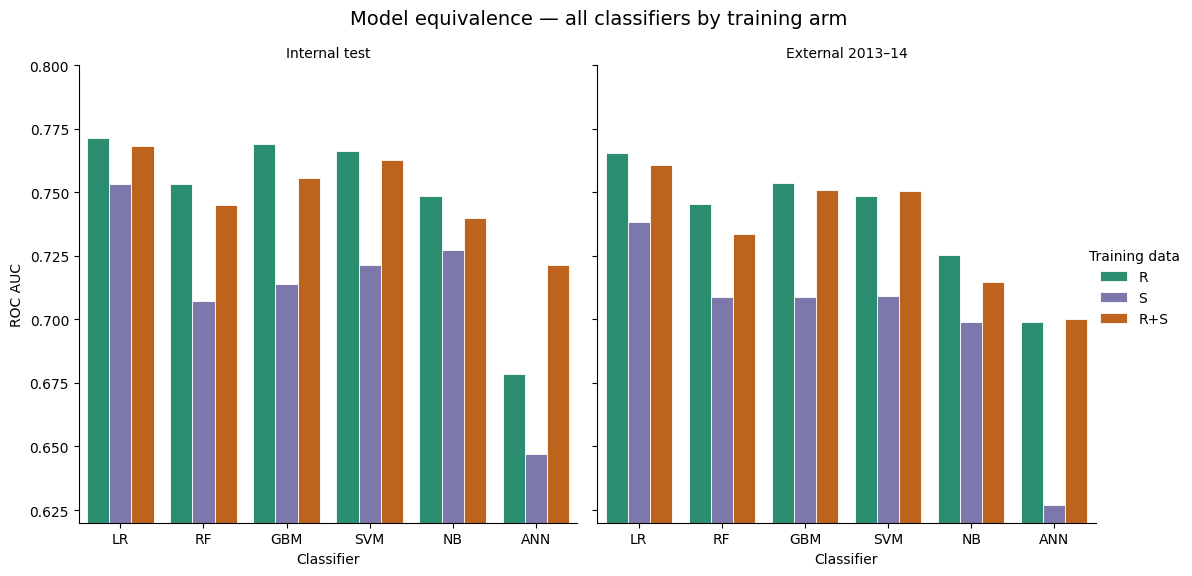

In [10]:
from sklearn.metrics import roc_curve

ARM_ORDER = ['R (real)', 'S (synthetic)', 'R+S (augmented)']
ARM_LABELS = {'R (real)': 'R', 'S (synthetic)': 'S', 'R+S (augmented)': 'R+S'}
MODEL_ORDER = ['LR', 'RF', 'GBM', 'SVM', 'NB', 'ANN']
ARM_PALETTE = {'R': '#1b9e77', 'S': '#7570b3', 'R+S': '#d95f02'}

plot_long = pd.concat([
    internal_table.assign(test_set='Internal test'),
    external_table.assign(test_set='External 2013–14'),
], ignore_index=True)
plot_long['arm_short'] = plot_long['arm'].map(ARM_LABELS)
plot_long['arm_short'] = pd.Categorical(
    plot_long['arm_short'], categories=['R', 'S', 'R+S'], ordered=True,
)
plot_long['model'] = pd.Categorical(plot_long['model'], categories=MODEL_ORDER, ordered=True)

g = sns.catplot(
    data=plot_long,
    kind='bar',
    x='model',
    y='AUC',
    hue='arm_short',
    col='test_set',
    col_order=['Internal test', 'External 2013–14'],
    order=MODEL_ORDER,
    hue_order=['R', 'S', 'R+S'],
    palette=ARM_PALETTE,
    height=5.5,
    aspect=1.0,
    edgecolor='white',
    linewidth=0.6,
)
g.set(ylim=(0.62, 0.80))
g.set_axis_labels('Classifier', 'ROC AUC')
g.set_titles('{col_name}')
for ax in g.axes.flat:
    ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
g._legend.set_title('Training data')
g.fig.suptitle(
    'Model equivalence — all classifiers by training arm',
    y=1.04,
    fontsize=14,
)
g.savefig(FIGURES_DIR / 'equivalence_auc_all_models_bars.png', dpi=150, bbox_inches='tight')
plt.show()

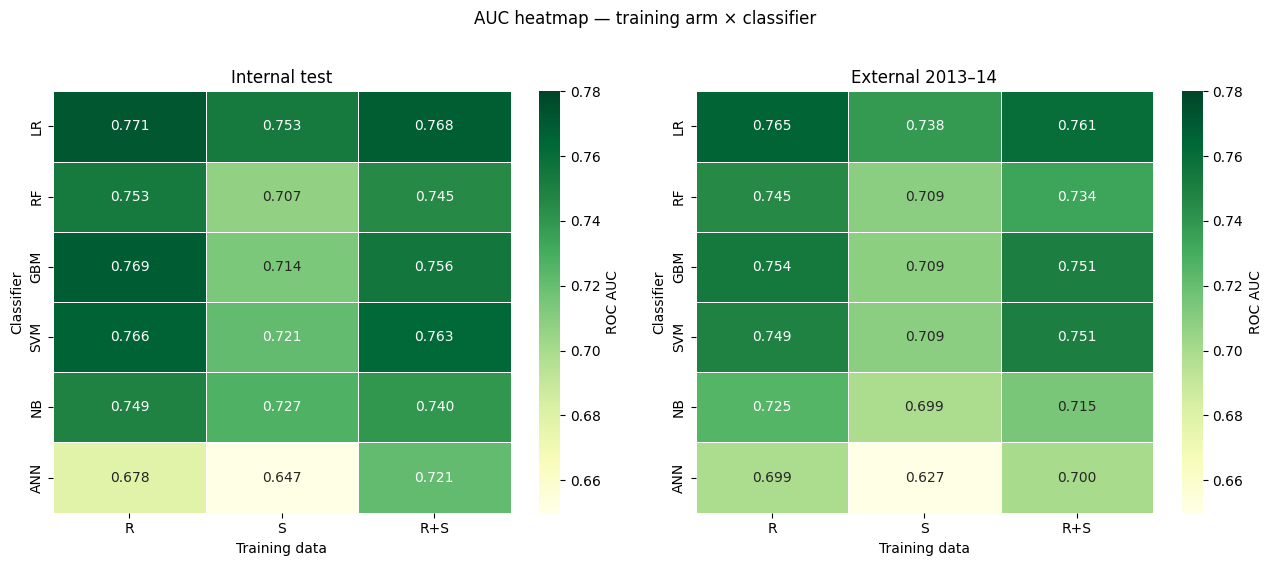

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, table, title in zip(
    axes,
    [internal_table, external_table],
    ['Internal test', 'External 2013–14'],
):
    pivot = table.pivot(index='model', columns='arm', values='AUC')
    pivot = pivot.reindex(MODEL_ORDER)
    pivot = pivot[[col for col in ARM_ORDER if col in pivot.columns]]
    pivot.columns = [ARM_LABELS[col] for col in pivot.columns]
    sns.heatmap(
        pivot,
        annot=True,
        fmt='.3f',
        cmap='YlGn',
        vmin=0.65,
        vmax=0.78,
        ax=ax,
        cbar_kws={'label': 'ROC AUC'},
        linewidths=0.5,
        linecolor='white',
    )
    ax.set_title(title)
    ax.set_xlabel('Training data')
    ax.set_ylabel('Classifier')

fig.suptitle('AUC heatmap — training arm × classifier', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'equivalence_auc_all_models_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

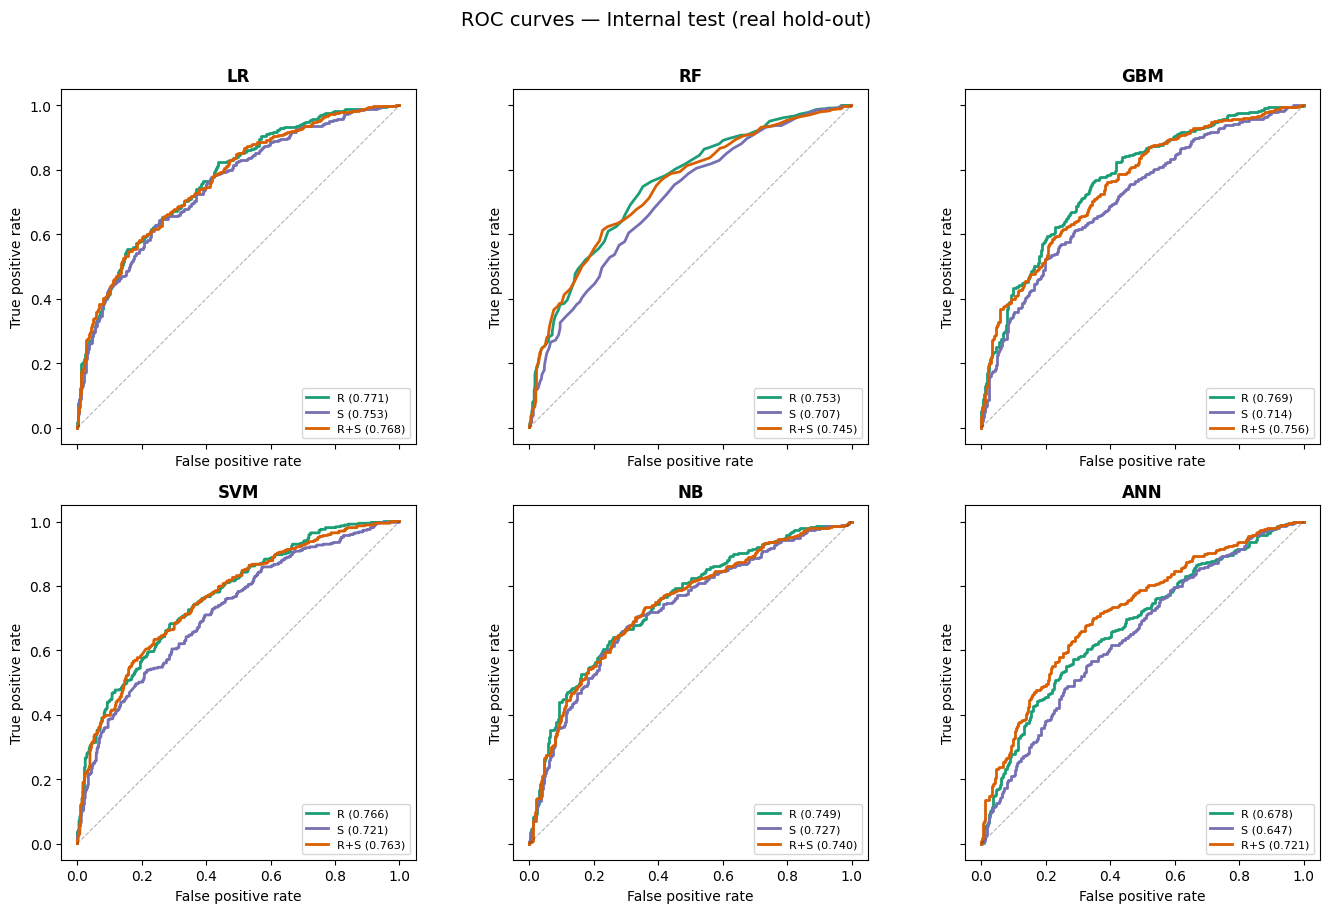

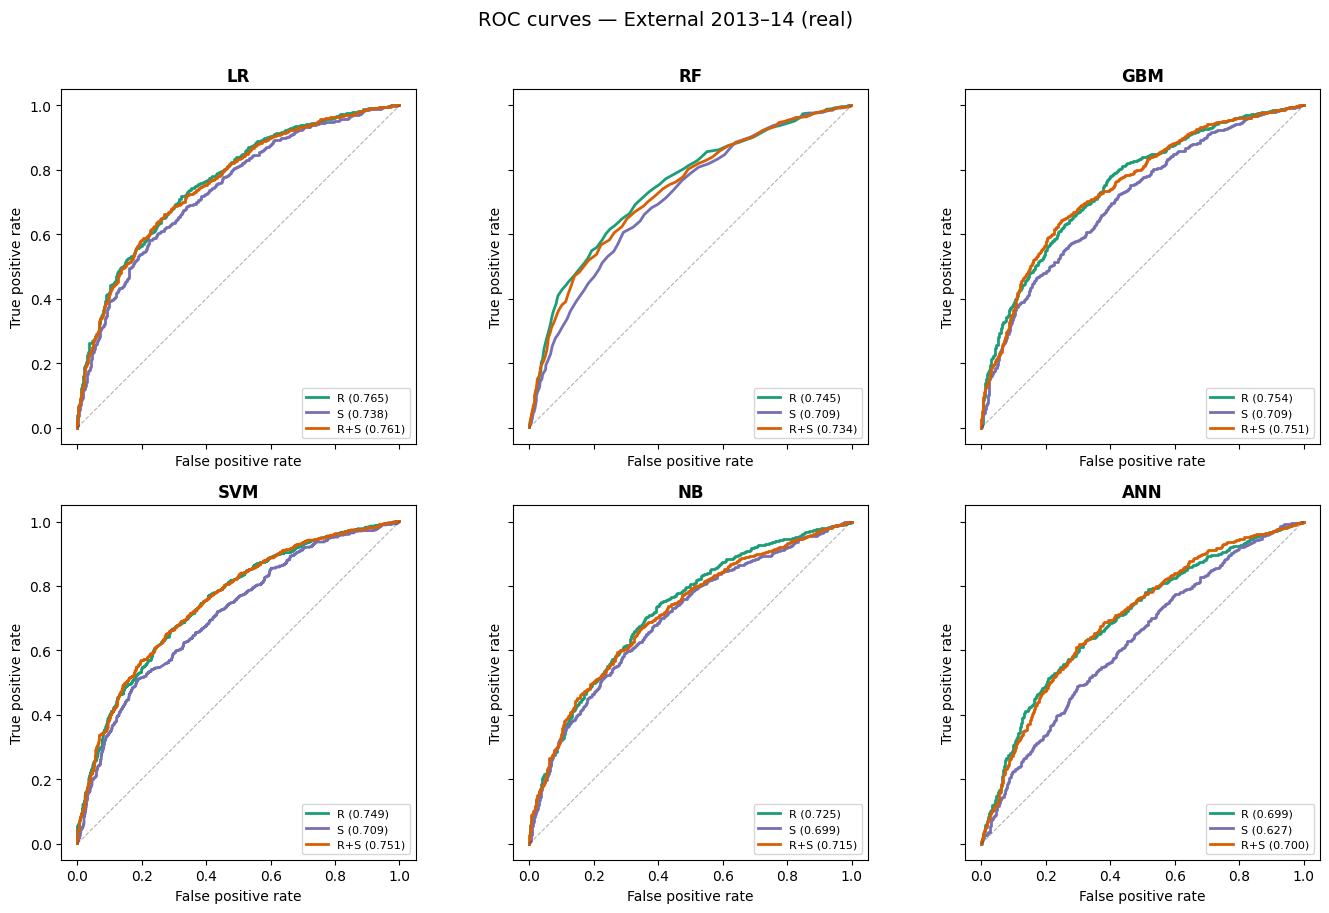

In [9]:
def plot_roc_grid(results_dict, test_label, save_path):
    """One subplot per classifier; R / S / R+S overlaid."""
    fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
    for ax, model in zip(axes.flat, MODEL_ORDER):
        for arm in ARM_ORDER:
            key = f'{arm} | {model}'
            payload = results_dict[key]
            fpr, tpr, _ = roc_curve(payload['y_true'], payload['y_proba'])
            short = ARM_LABELS[arm]
            ax.plot(
                fpr,
                tpr,
                label=f'{short} ({payload["auc"]:.3f})',
                color=ARM_PALETTE[short],
                linewidth=2,
            )
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=0.8)
        ax.set_title(model, fontweight='bold')
        ax.set_xlabel('False positive rate')
        ax.set_ylabel('True positive rate')
        ax.legend(loc='lower right', fontsize=8)
        ax.set_aspect('equal')
    fig.suptitle(f'ROC curves — {test_label}', y=1.01, fontsize=14)
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_roc_grid(
    results_internal,
    'Internal test (real hold-out)',
    FIGURES_DIR / 'equivalence_roc_all_models_internal.png',
)
plot_roc_grid(
    results_external,
    'External 2013–14 (real)',
    FIGURES_DIR / 'equivalence_roc_all_models_external.png',
)

## 5.7 Confusion matrices — all models

AUC compares **ranking**. Confusion matrices show **decisions** at sklearn's default **0.5** probability cutoff (`predict`).

Each panel is Actual (rows) × Predicted (columns): class 0 = normal BMD, class 1 = low BMD. Sensitivity and specificity are on the title. Colour scale is shared across the three arms of each classifier so darker cells are comparable within a row.

Two grids: **internal test** and **external 2013–14**. Columns = training arm (R / S / R+S); rows = classifier.


=== Internal test (real hold-out) ===
            arm model  TN  FP  FN  TP  sensitivity  specificity   PPV   NPV  accuracy
       R (real)    LR 302 107 130 239        0.648        0.738 0.691 0.699     0.695
  S (synthetic)    LR 337  72 175 194        0.526        0.824 0.729 0.658     0.683
R+S (augmented)    LR 315  94 145 224        0.607        0.770 0.704 0.685     0.693
       R (real)    RF 314  95 156 213        0.577        0.768 0.692 0.668     0.677
  S (synthetic)    RF 326  83 204 165        0.447        0.797 0.665 0.615     0.631
R+S (augmented)    RF 320  89 155 214        0.580        0.782 0.706 0.674     0.686
       R (real)   GBM 311  98 139 230        0.623        0.760 0.701 0.691     0.695
  S (synthetic)   GBM 332  77 195 174        0.472        0.812 0.693 0.630     0.650
R+S (augmented)   GBM 310  99 148 221        0.599        0.758 0.691 0.677     0.683
       R (real)   SVM 317  92 149 220        0.596        0.775 0.705 0.680     0.690
  S (synthetic) 

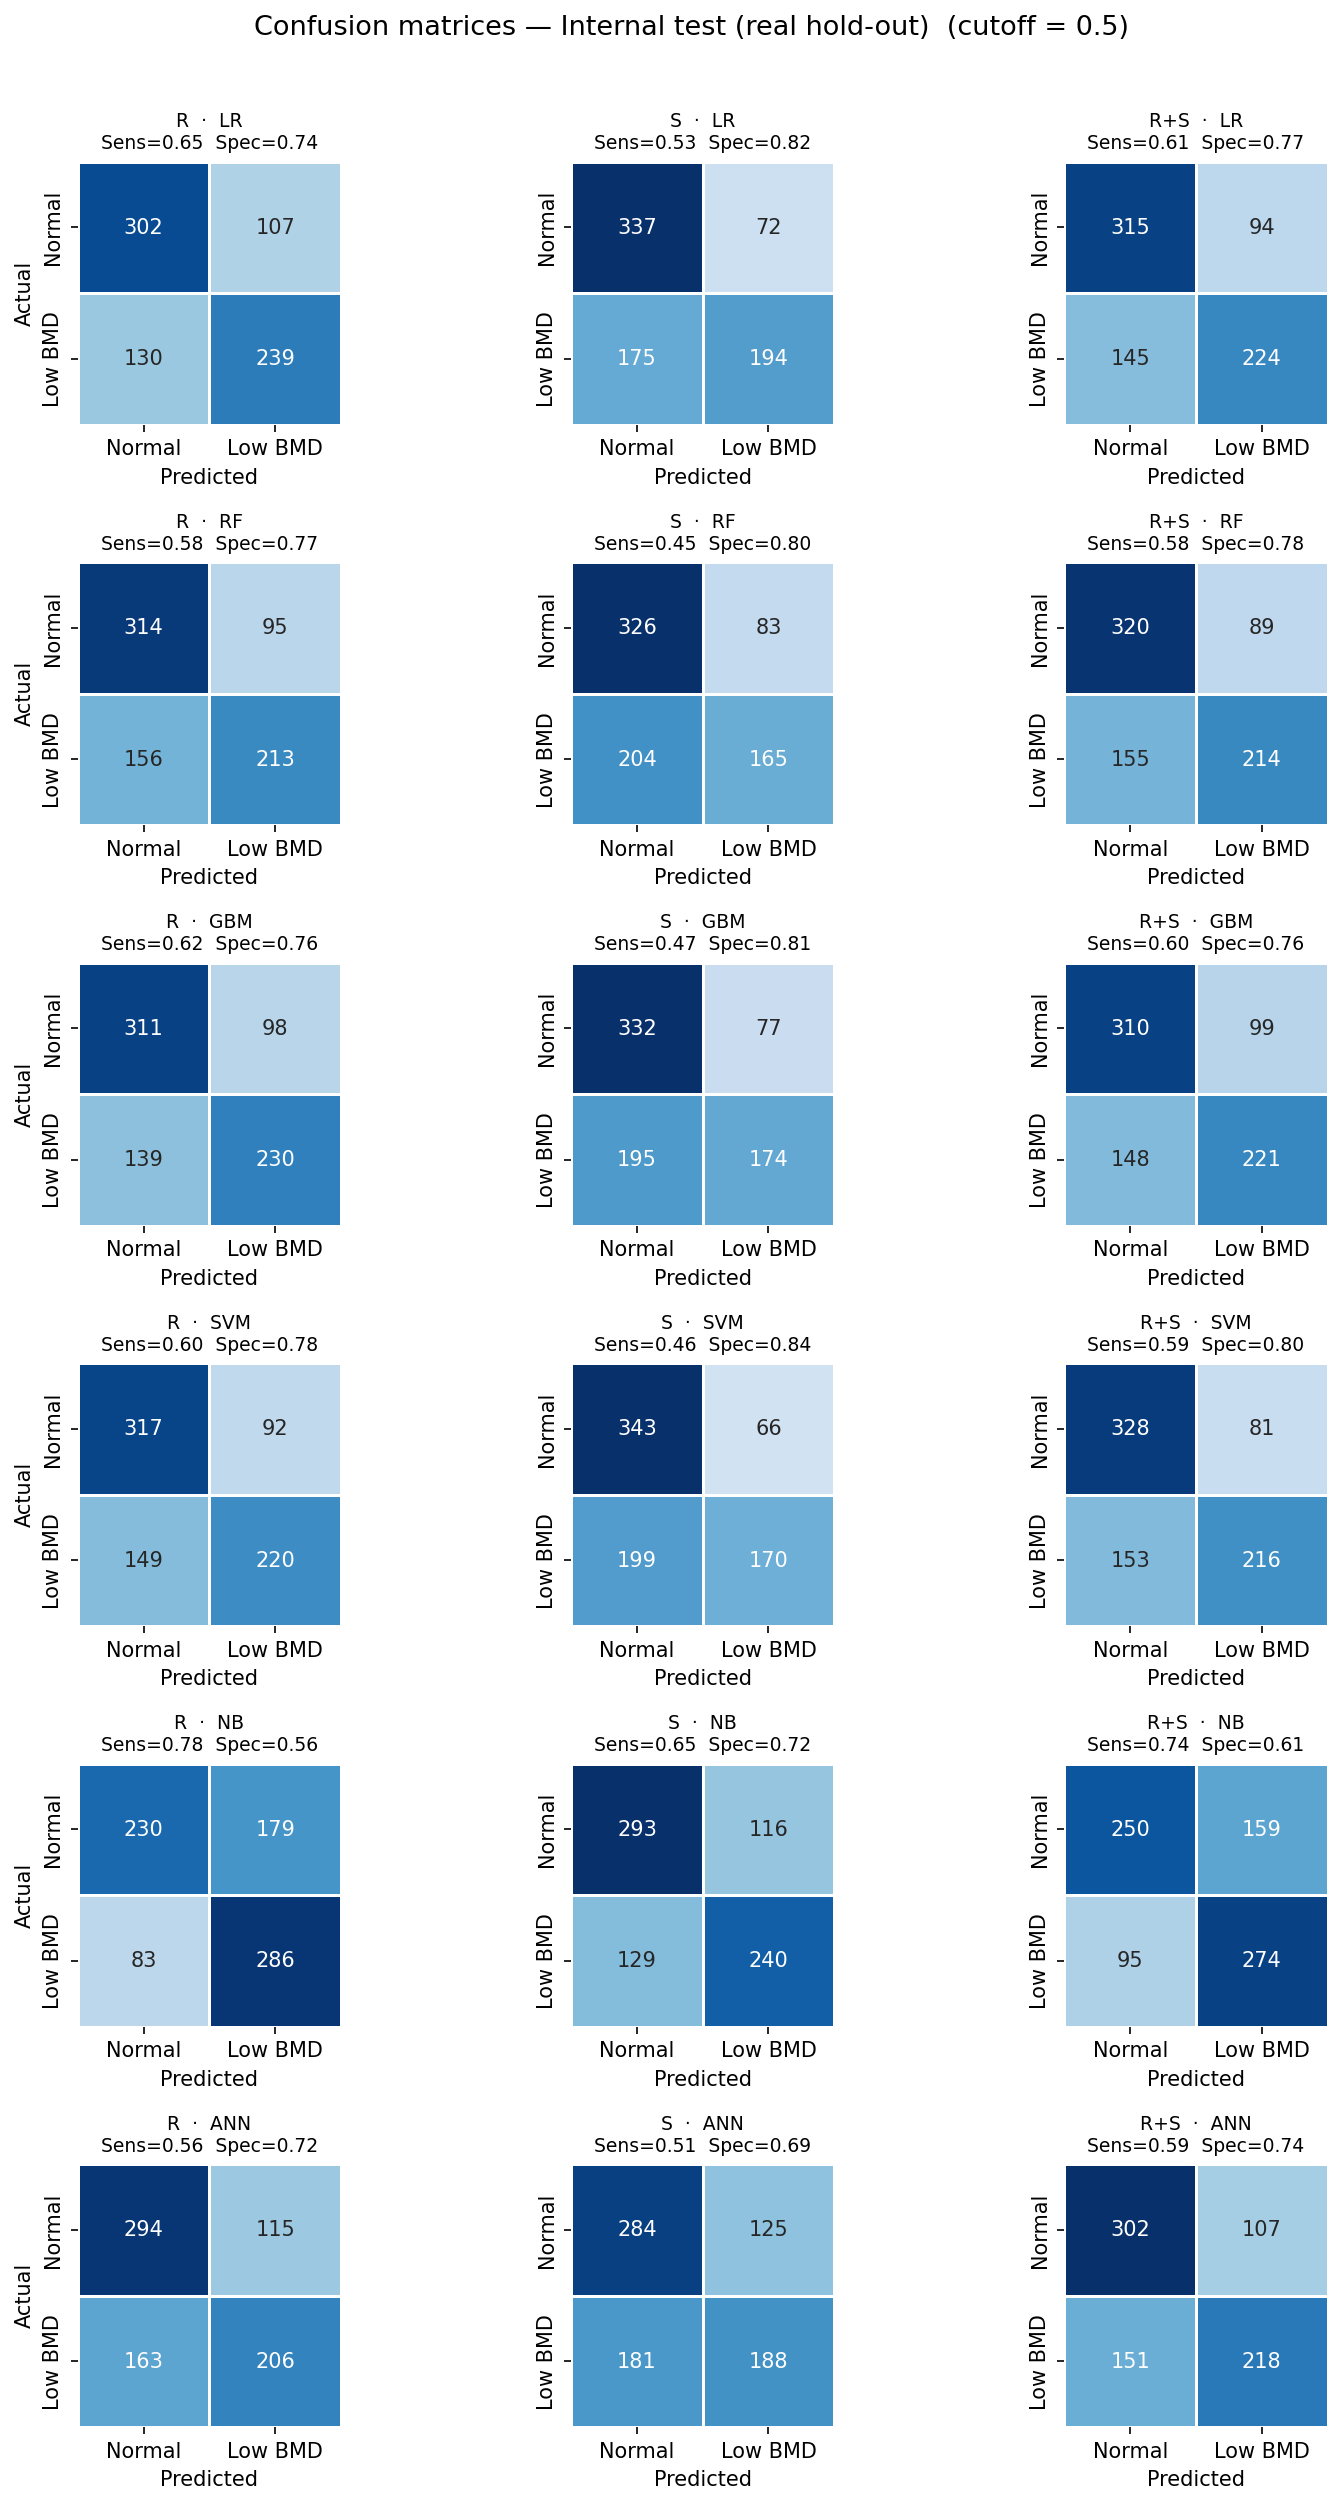

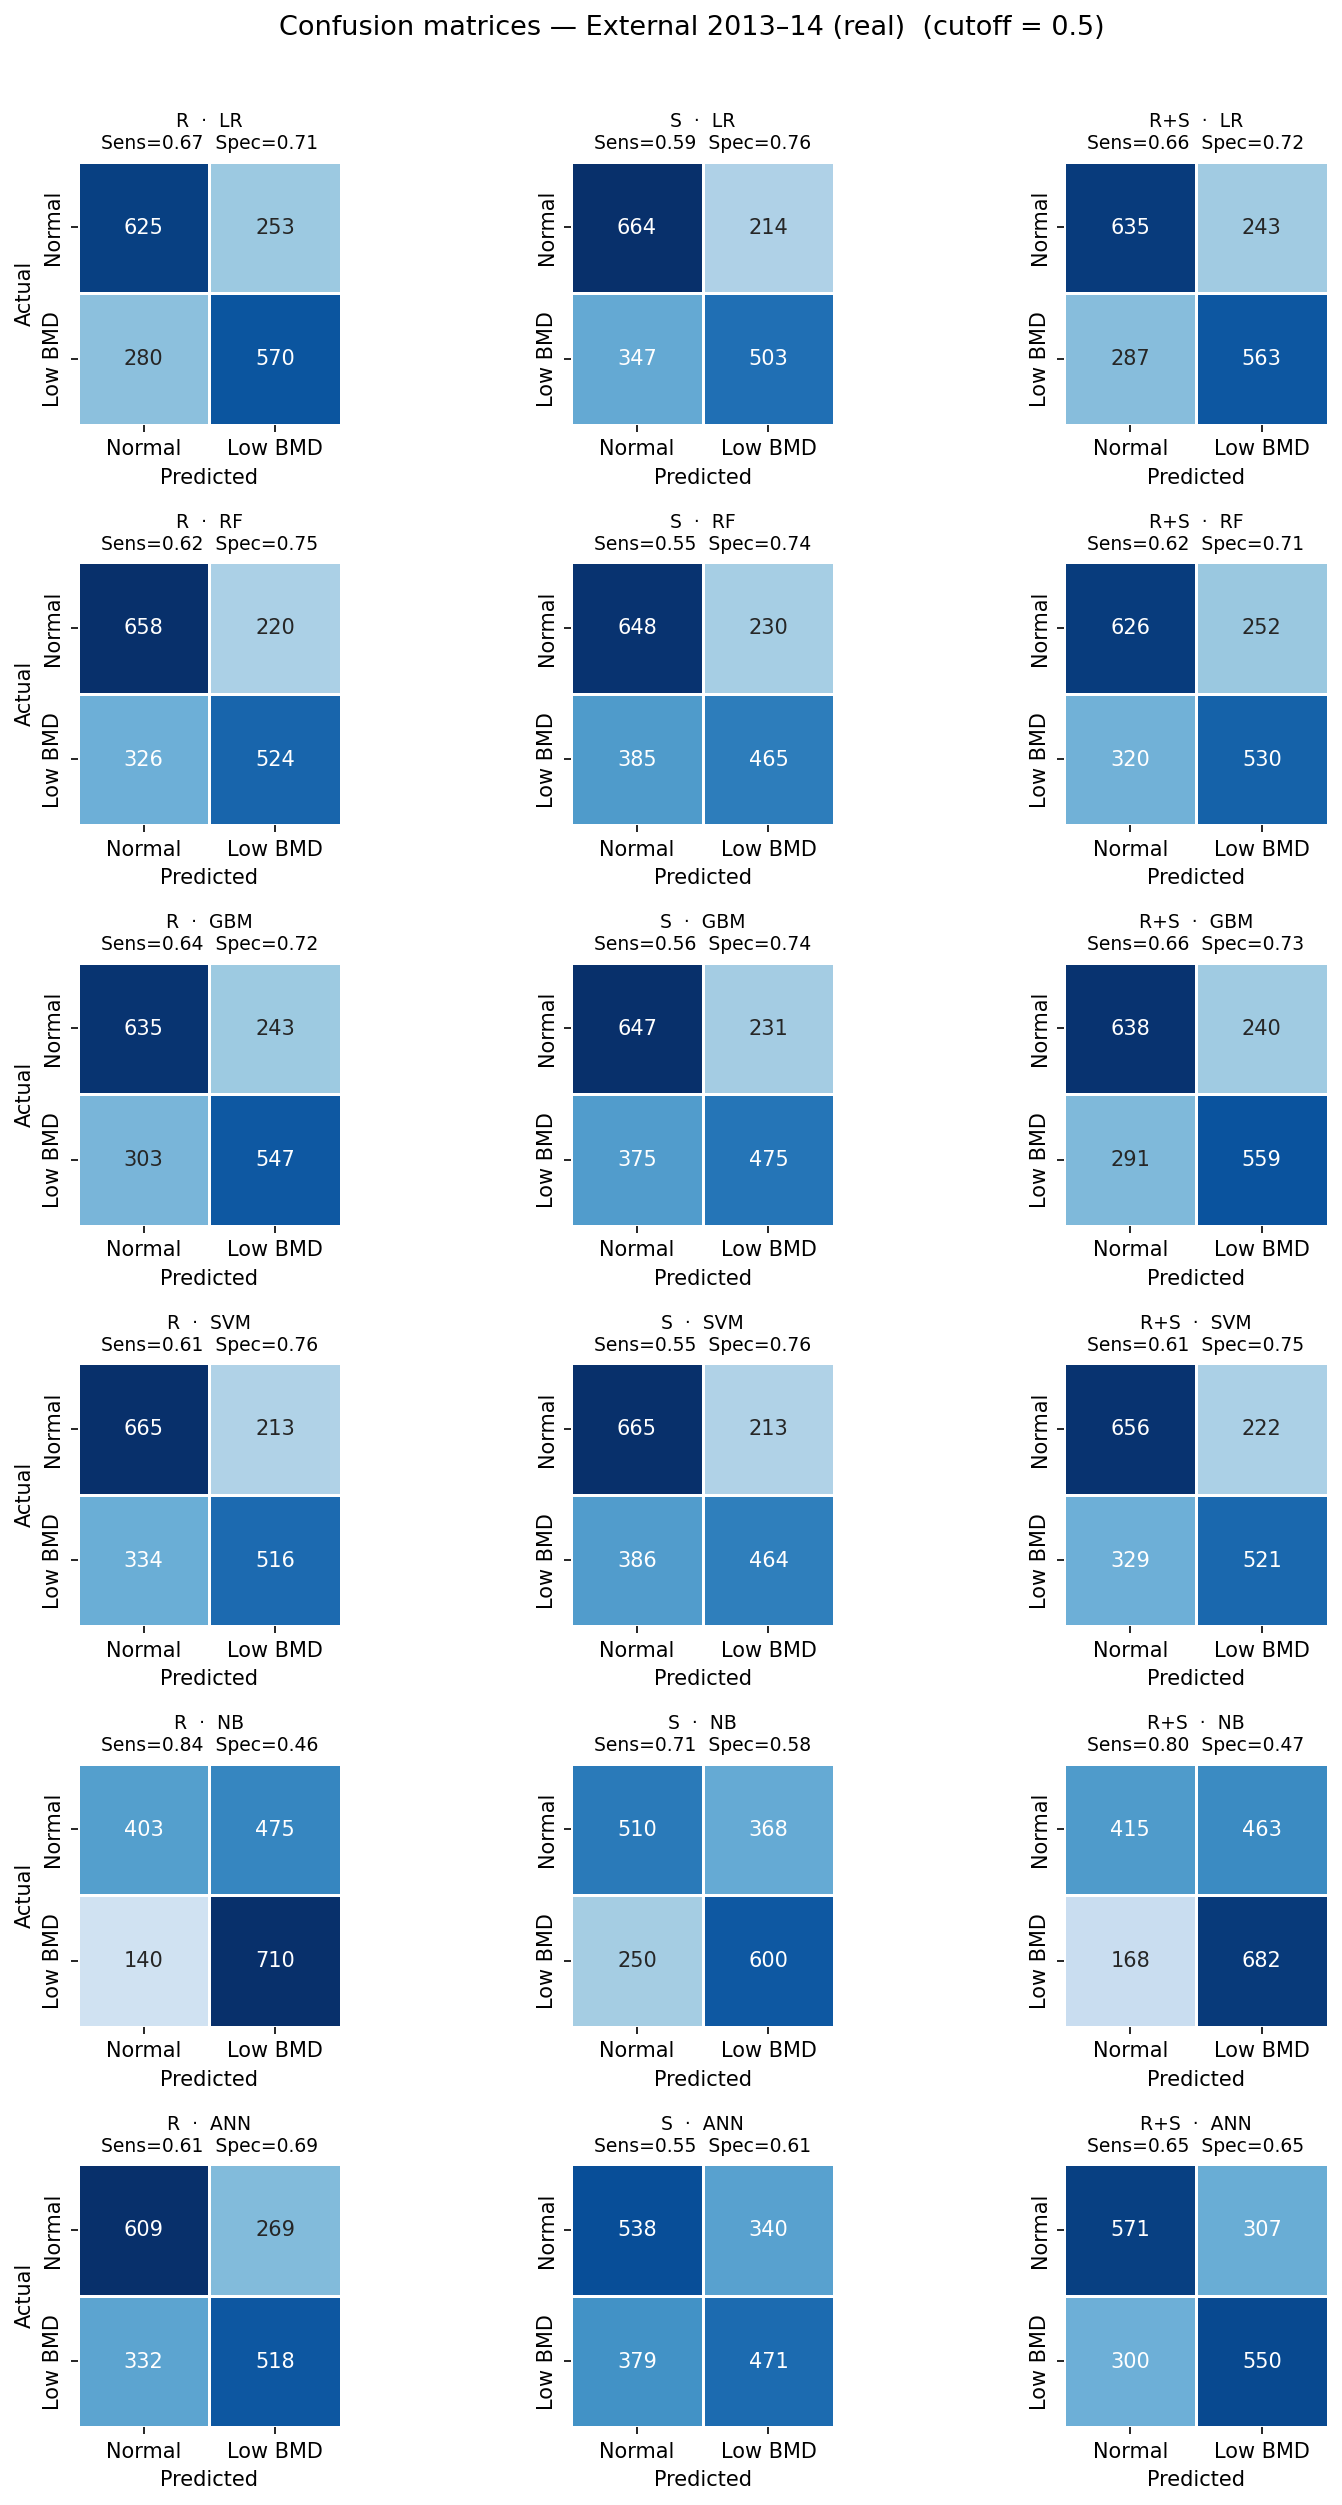

In [18]:
def cm_metrics(cm):
    tn, fp, fn, tp = cm.ravel()
    n = tn + fp + fn + tp
    return {
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
        'sensitivity': tp / (tp + fn) if (tp + fn) else float('nan'),
        'specificity': tn / (tn + fp) if (tn + fp) else float('nan'),
        'PPV': tp / (tp + fp) if (tp + fp) else float('nan'),
        'NPV': tn / (tn + fn) if (tn + fn) else float('nan'),
        'accuracy': (tp + tn) / n if n else float('nan'),
    }


def confusion_table(results):
    rows = []
    for key, val in results.items():
        arm, model = key.split(' | ')
        rows.append({'arm': arm, 'model': model, **cm_metrics(val['cm'])})
    table = pd.DataFrame(rows)
    table['arm'] = pd.Categorical(table['arm'], categories=ARM_ORDER, ordered=True)
    table['model'] = pd.Categorical(table['model'], categories=MODEL_ORDER, ordered=True)
    return table.sort_values(['model', 'arm']).reset_index(drop=True)


def plot_confusion_grid(results_dict, test_label, save_path):
    """Rows = classifiers, columns = training arms. Shared colour scale per row."""
    n_models, n_arms = len(MODEL_ORDER), len(ARM_ORDER)
    fig, axes = plt.subplots(
        n_models, n_arms, figsize=(10.5, 16.5), squeeze=False,
    )
    for i, model in enumerate(MODEL_ORDER):
        cms = [results_dict[f'{arm} | {model}']['cm'] for arm in ARM_ORDER]
        vmax = max(cm.max() for cm in cms)
        for j, (arm, cm) in enumerate(zip(ARM_ORDER, cms)):
            ax = axes[i, j]
            stats = cm_metrics(cm)
            sns.heatmap(
                cm,
                annot=True,
                fmt='d',
                cmap='Blues',
                vmin=0,
                vmax=vmax,
                ax=ax,
                cbar=False,
                square=True,
                linewidths=0.6,
                linecolor='white',
                xticklabels=['Normal', 'Low BMD'],
                yticklabels=['Normal', 'Low BMD'],
            )
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual' if j == 0 else '')
            ax.set_title(
                f"{ARM_LABELS[arm]}  ·  {model}\n"
                f"Sens={stats['sensitivity']:.2f}  Spec={stats['specificity']:.2f}",
                fontsize=9,
            )
    fig.suptitle(
        f'Confusion matrices — {test_label}  (cutoff = 0.5)',
        y=1.01,
        fontsize=13,
    )
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return fig


cm_internal = confusion_table(results_internal)
cm_external = confusion_table(results_external)

print('=== Internal test (real hold-out) ===')
print(cm_internal.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print('\n=== External 2013–2014 (real) ===')
print(cm_external.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

cm_internal.to_csv(FIGURES_DIR / 'equivalence_cm_internal.csv', index=False)
cm_external.to_csv(FIGURES_DIR / 'equivalence_cm_external.csv', index=False)

plot_confusion_grid(
    results_internal,
    'Internal test (real hold-out)',
    FIGURES_DIR / 'equivalence_cm_all_models_internal.png',
)
plot_confusion_grid(
    results_external,
    'External 2013–14 (real)',
    FIGURES_DIR / 'equivalence_cm_all_models_external.png',
)


**Next:** `6_LR_SHAP_ANALYSIS.ipynb` explains the three logistic-regression arms with SHAP, to check whether arms with similar AUC also agree on *why* they predict low BMD.